# تحلیل جریان در شبکه تصادفی دوبعدی

این دفترچه مدل را روی یک نمونه اجرا و نتایج کامل ذخیره‌شده را بررسی می‌کند. گزارش تفصیلی فارسی در `reports/report_fa.pdf` و ارائه در `reports/presentation_en.pdf` است. برای اجرای مجدد همه ۲۴۸٬۱۸۸ ارزیابی، فرمان `make all` را از ریشه مخزن اجرا کنید.

All variables are dimensionless. One global connectivity probability is drawn per realization.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd() if (Path.cwd()/"results").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT/"src"))
from flow_network import Lattice
RES = ROOT/"results"
FIG = ROOT/"reports"/"figures"

## اجرای نمونه و بررسی بقای جریان

جزیره‌های جدا از مرزها جریان صفر و هد مطلق نامعین دارند. حل‌گر برای رفع تکینی به آن‌ها رسانایی مصنوعی اضافه نمی‌کند.

In [2]:
grid = Lattice(25)
rng = np.random.default_rng(42)
g = grid.generate(p=0.6, sigma=1, rng=rng)
result = grid.solve(g, details=True)
assert np.isclose(result.conductance, result.outlet_flow, atol=1e-10)
assert np.isclose(result.conductance, result.energy, atol=1e-10)
{"G_eff":result.conductance, "spanning":result.spanning,
 "max_balance_residual":result.max_residual, "floating_nodes":result.floating_nodes}

{'G_eff': 0.10089357012839803,
 'spanning': True,
 'max_balance_residual': 2.23362588190959e-15,
 'floating_nodes': 43}

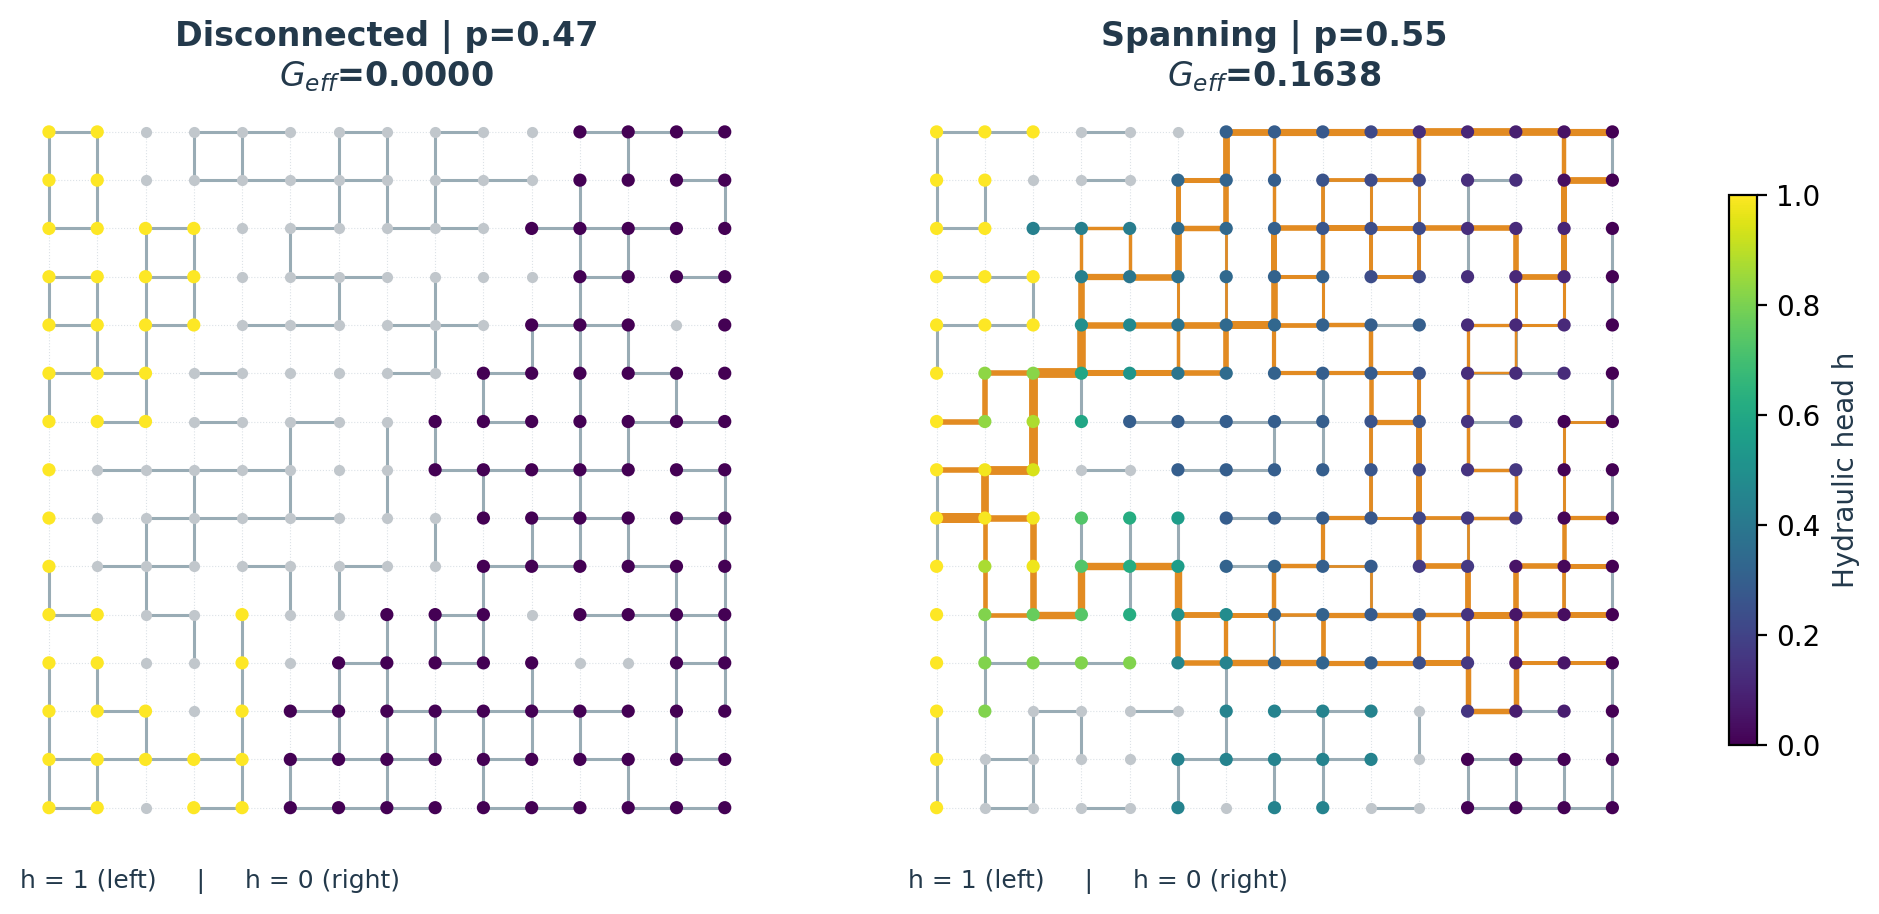

In [3]:
display(Image(filename=str(FIG/"01_network.png"), width=950))

## آمار عدم‌قطعیت

۹ سناریو، هرکدام ۱۰٬۰۰۰ نمونه مستقل. سطرهای متناظر میان سناریوها با اعداد تصادفی مشترک جفت شده‌اند. فاصله اطمینان میانگین، خطای مونت‌کارلو را نشان می‌دهد و بازه پیش‌بینی برای یک شبکه تازه نیست.

,delta,sigma,samples,mean,mean_ci_low,mean_ci_high,p_zero,median,q95,positive_mean
0,0.00,0.0,10000,0.026201,0.025628,0.026773,0.4794,0.025327,0.080527,0.050328
1,0.00,1.0,10000,0.018253,0.017839,0.018668,0.4794,0.015019,0.059038,0.035062
2,0.00,2.0,10000,0.007702,0.007499,0.007906,0.4794,0.002820,0.028776,0.014795
3,0.10,0.0,10000,0.049905,0.048688,0.051123,0.4794,0.028517,0.177462,0.095861
4,0.10,1.0,10000,0.036807,0.035876,0.037738,0.4794,0.017439,0.136003,0.070701
5,0.10,2.0,10000,0.018326,0.017806,0.018846,0.4794,0.004002,0.075167,0.035202
6,0.25,0.0,10000,0.122156,0.119044,0.125268,0.4862,0.031109,0.449080,0.237750
7,0.25,1.0,10000,0.099231,0.096603,0.101859,0.4862,0.019531,0.383825,0.193132
8,0.25,2.0,10000,0.063851,0.061990,0.065712,0.4862,0.004982,0.276014,0.124272


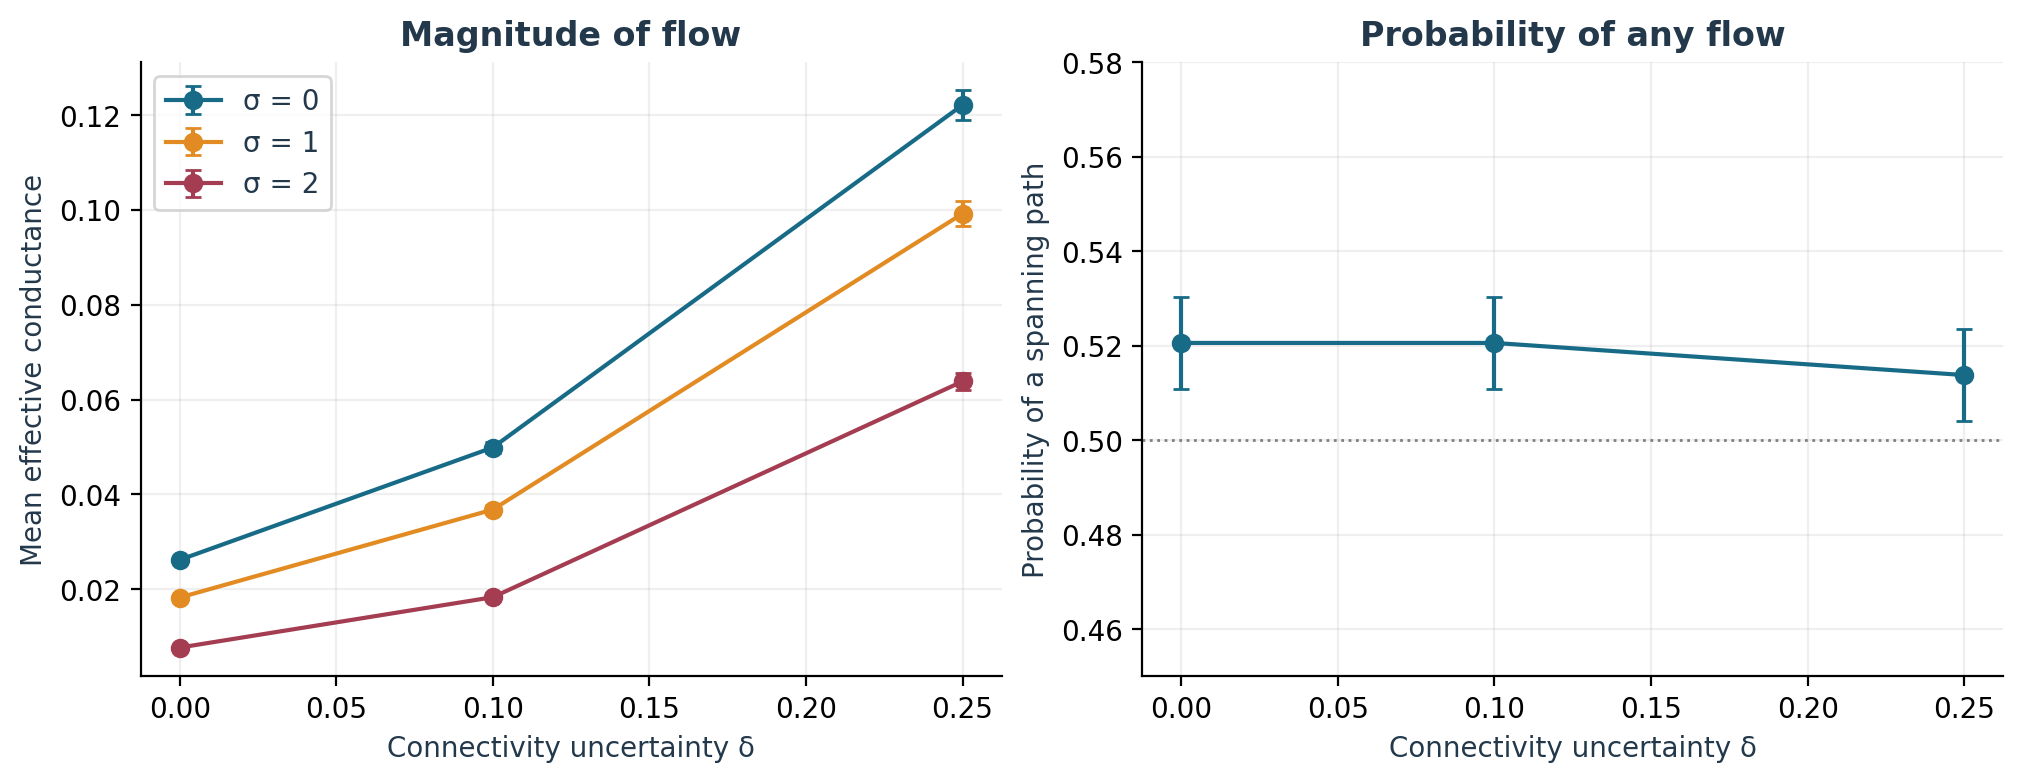

In [4]:
summary = pd.read_csv(RES/"scenario_summary.csv")
assert len(summary)==9 and (summary.samples==10000).all()
display(summary[["delta","sigma","samples","mean","mean_ci_low","mean_ci_high",
                 "p_zero","median","q95","positive_mean"]])
display(Image(filename=str(FIG/"02_uncertainty.png"), width=950))

In [5]:
samples = pd.read_csv(RES/"scenario_samples.csv.gz")
ref = samples[(samples.delta==0.25)&(samples.sigma==1)]
g = ref.geff.to_numpy()
assert len(g)==10000
{"mean":g.mean(), "p_zero":float(np.mean(g==0)), "median":np.median(g),
 "q95":np.quantile(g,0.95), "conditional_positive_mean":g[g>0].mean()}

{'mean': np.float64(0.09923103696372632),
 'p_zero': 0.4862,
 'median': np.float64(0.0195313508018394),
 'q95': np.float64(0.38382514204257506),
 'conditional_positive_mean': np.float64(0.19313164064563315)}

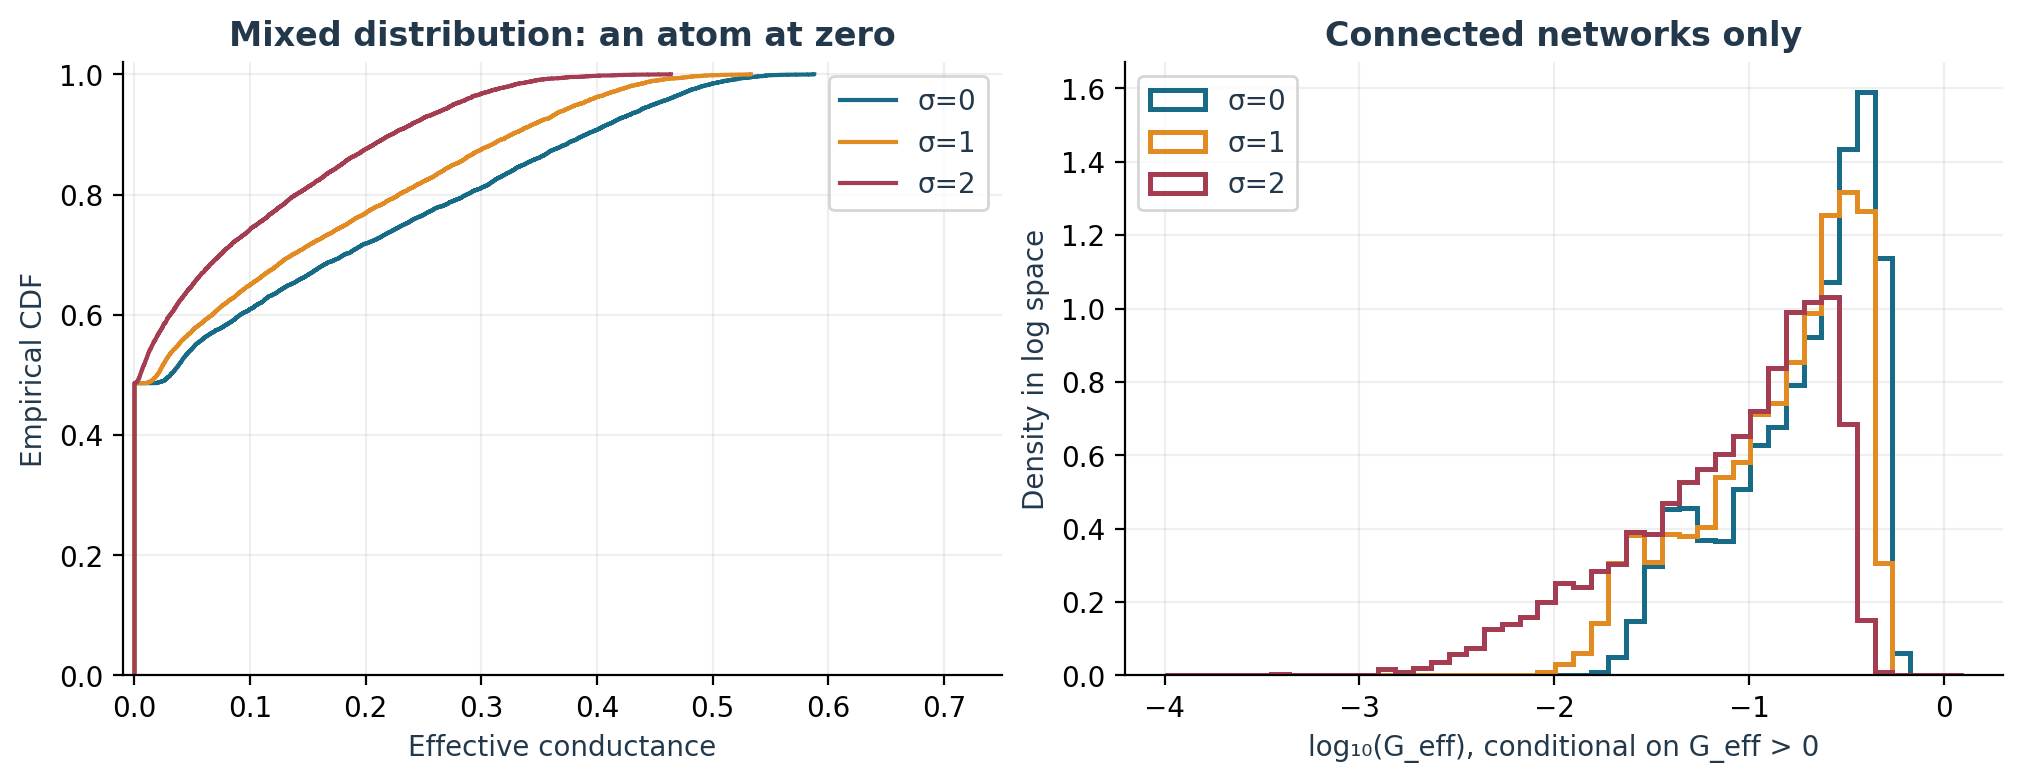

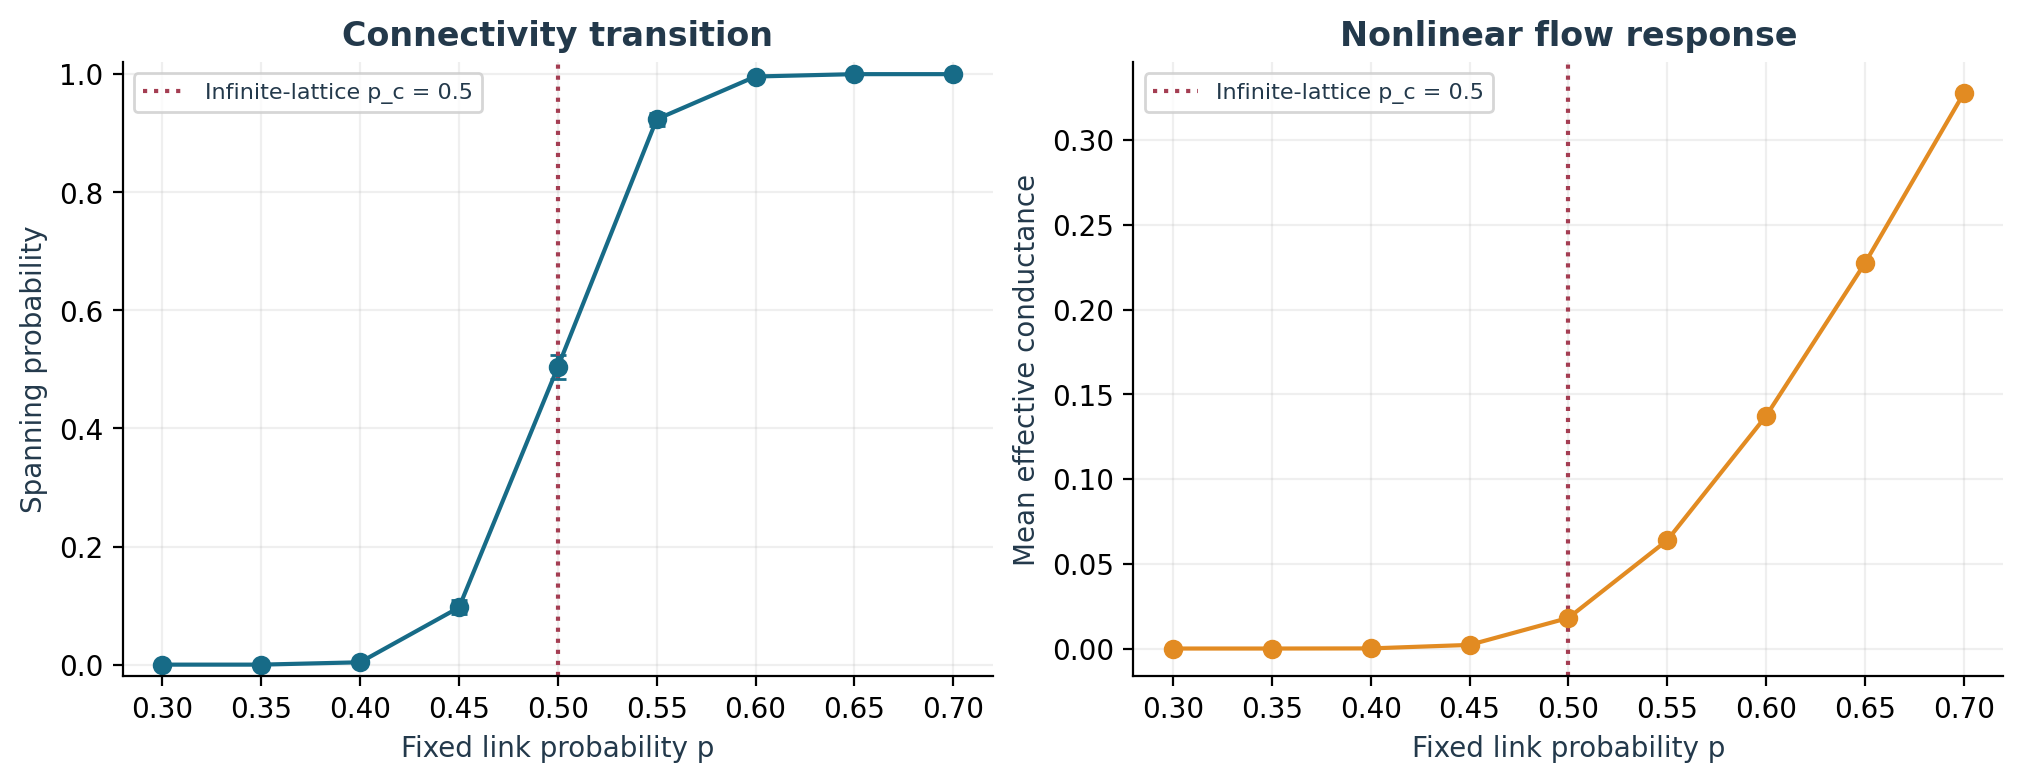

In [6]:
display(Image(filename=str(FIG/"03_distribution.png"), width=950))
display(Image(filename=str(FIG/"04_connectivity.png"), width=950))

## حساسیت گروهی سوبول

پنج گروه مستقل شامل δ، σ، متغیر نهفته U برای احتمال اتصال، میدان آرایش W و میدان رسانایی Z است. رابطه `p=0.5+δU` مانع فرض استقلال اشتباه δ و p می‌شود. شاخص‌های کل هم‌پوشانی دارند و نباید به‌عنوان سهم‌های مستقل جمع شوند.

,output,factor,first,first_low,first_high,total,total_low,total_high
0,geff,delta,0.095751,0.067788,0.122843,0.358039,0.341375,0.374863
1,geff,sigma,0.024910,0.004912,0.044252,0.060633,0.057590,0.063921
2,geff,p_latent,0.516257,0.496120,0.535836,0.824657,0.798828,0.855607
3,geff,topology,0.045815,0.027732,0.062827,0.104310,0.100168,0.108689
4,geff,conductance_field,0.010063,-0.007261,0.025598,0.010255,0.009575,0.010975
5,spanning,delta,0.004072,-0.010127,0.019063,0.243794,0.234029,0.253596
6,spanning,sigma,0.006392,-0.009026,0.021266,0.000000,0.000000,0.000000
7,spanning,p_latent,0.493491,0.480717,0.506591,0.788636,0.772710,0.804185
8,spanning,topology,0.156550,0.141408,0.172128,0.434849,0.422739,0.447459
9,spanning,conductance_field,0.006392,-0.009026,0.021266,0.000000,0.000000,0.000000


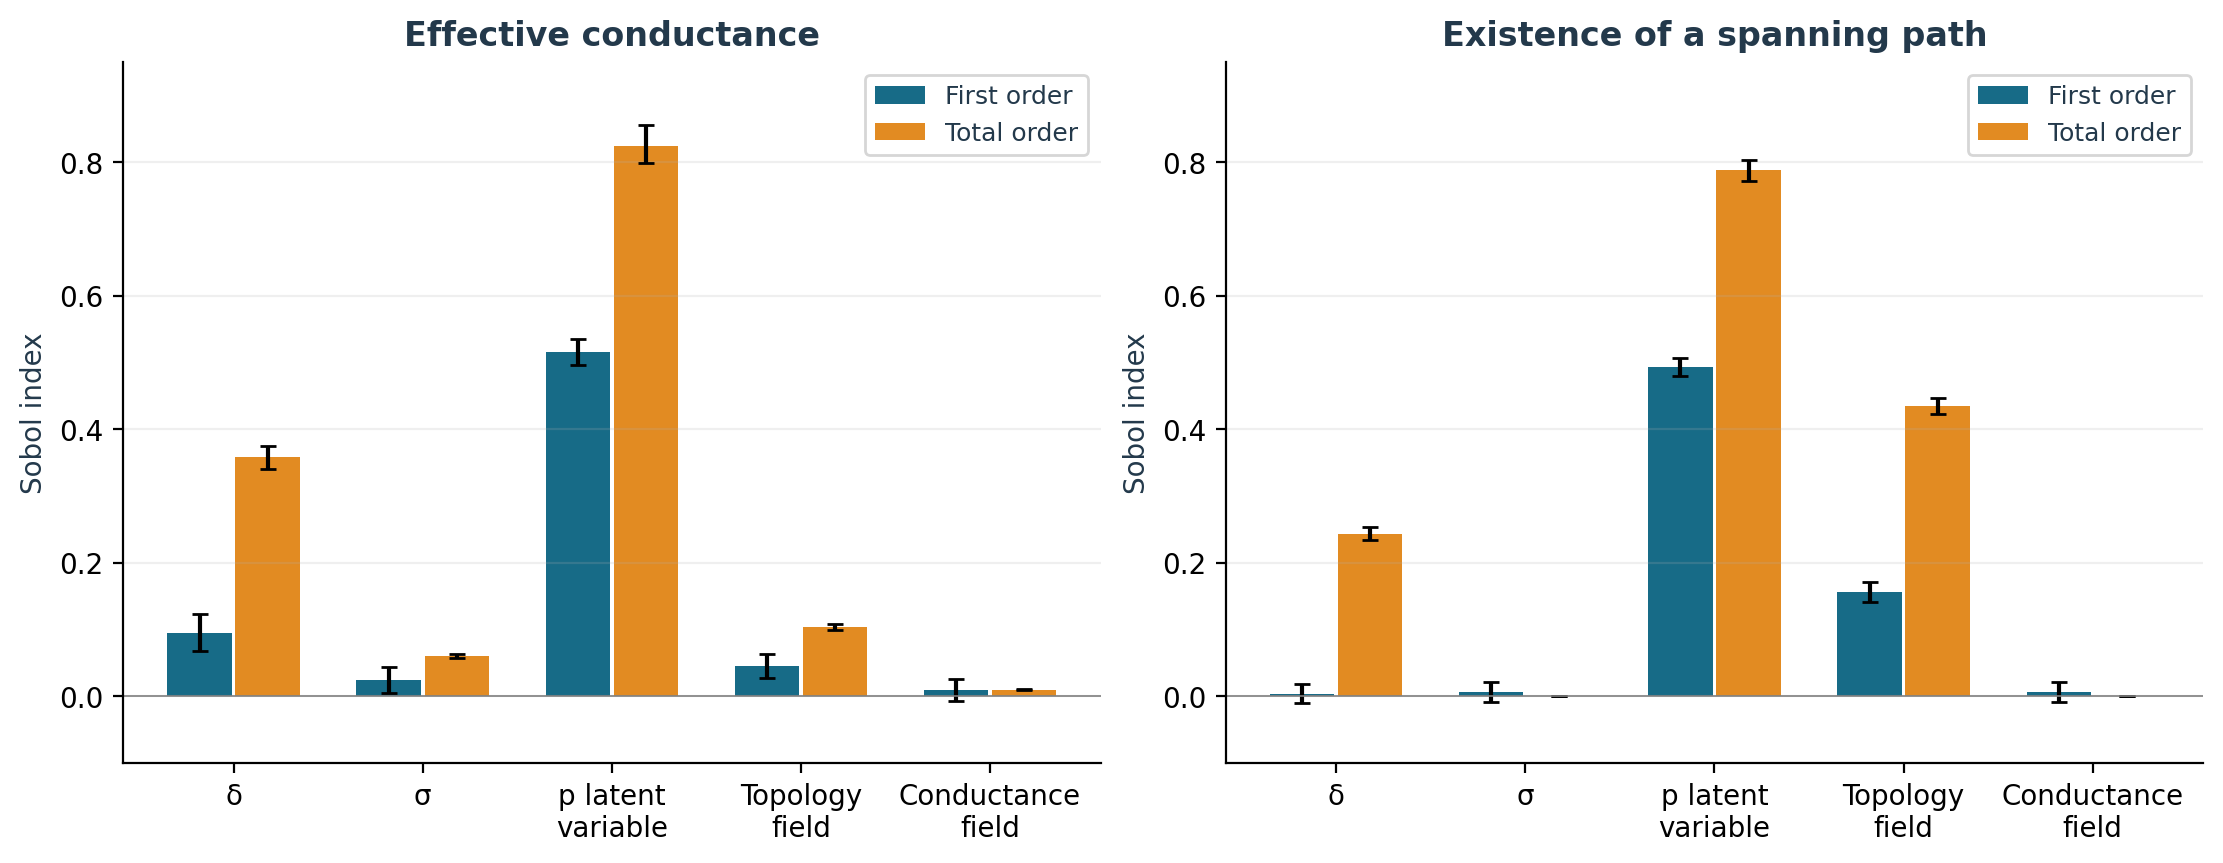

In [7]:
sobol = pd.read_csv(RES/"sobol_summary.csv")
display(sobol)
display(Image(filename=str(FIG/"05_sensitivity.png"), width=1050))

## همگرایی و کنترل میانگین رسانایی

تغییر اندازه شبکه، حساسیت به اندازه جامعه شبکه‌ها را بررسی می‌کند و همگرایی یک شبکه‌بندی پیوسته نیست. توزیع اصلی میانه رسانایی را ثابت نگه می‌دارد. کنترل میانگین ثابت از مقیاس‌کردن دقیق `G*=G exp(-σ²/2)` استفاده می‌کند.

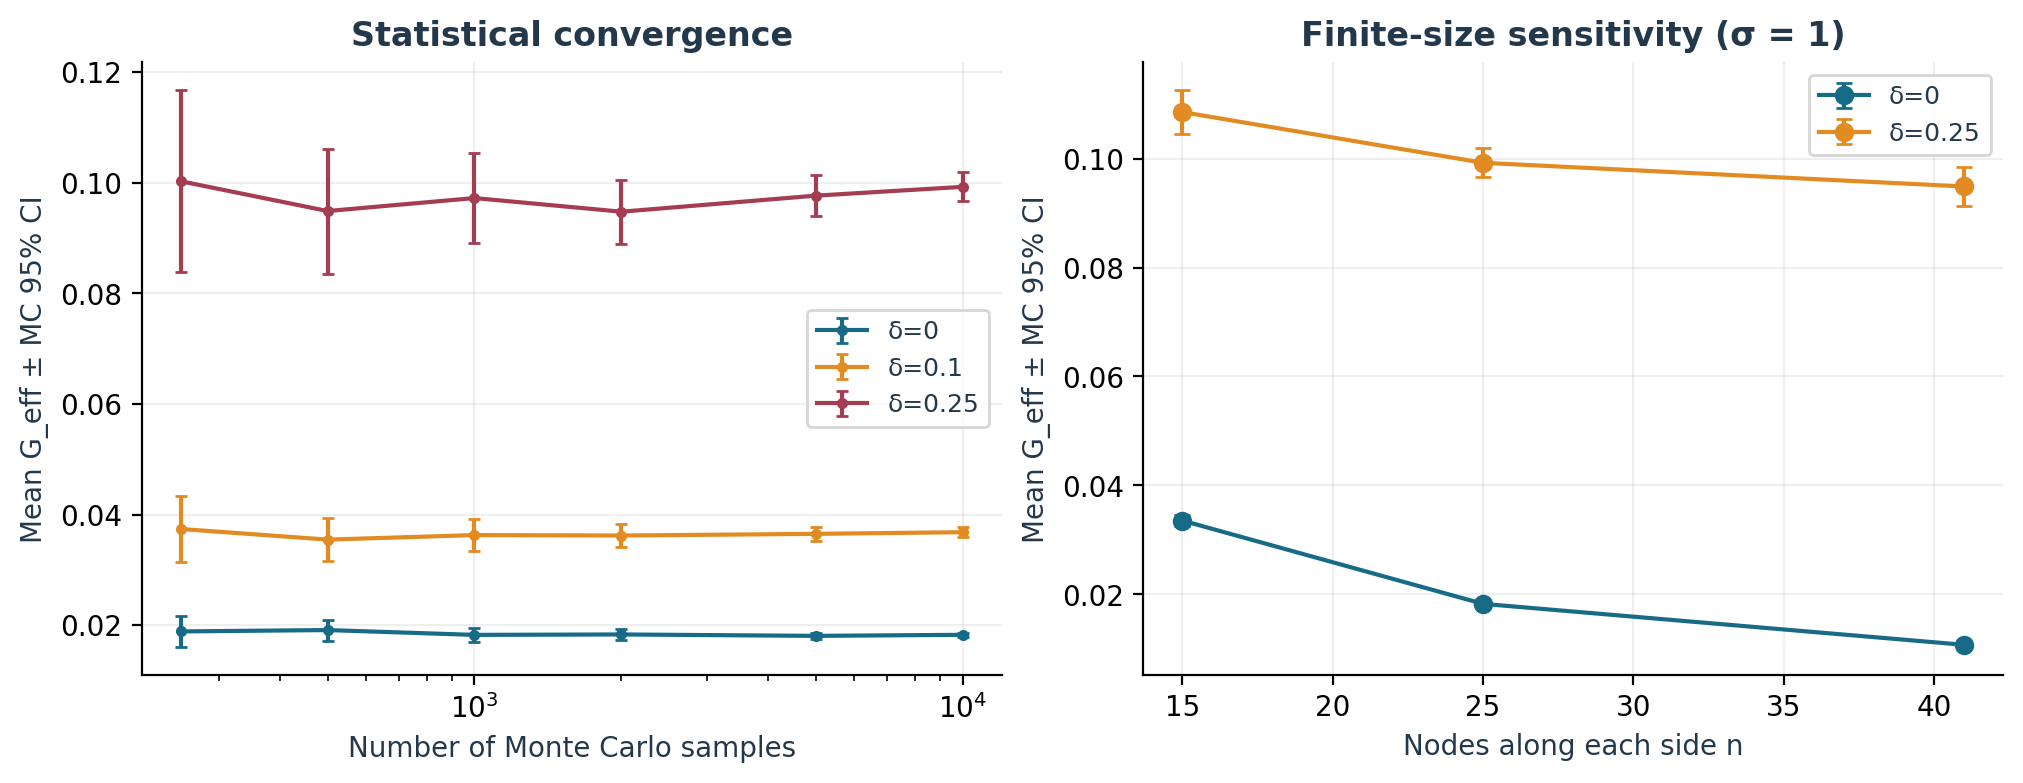

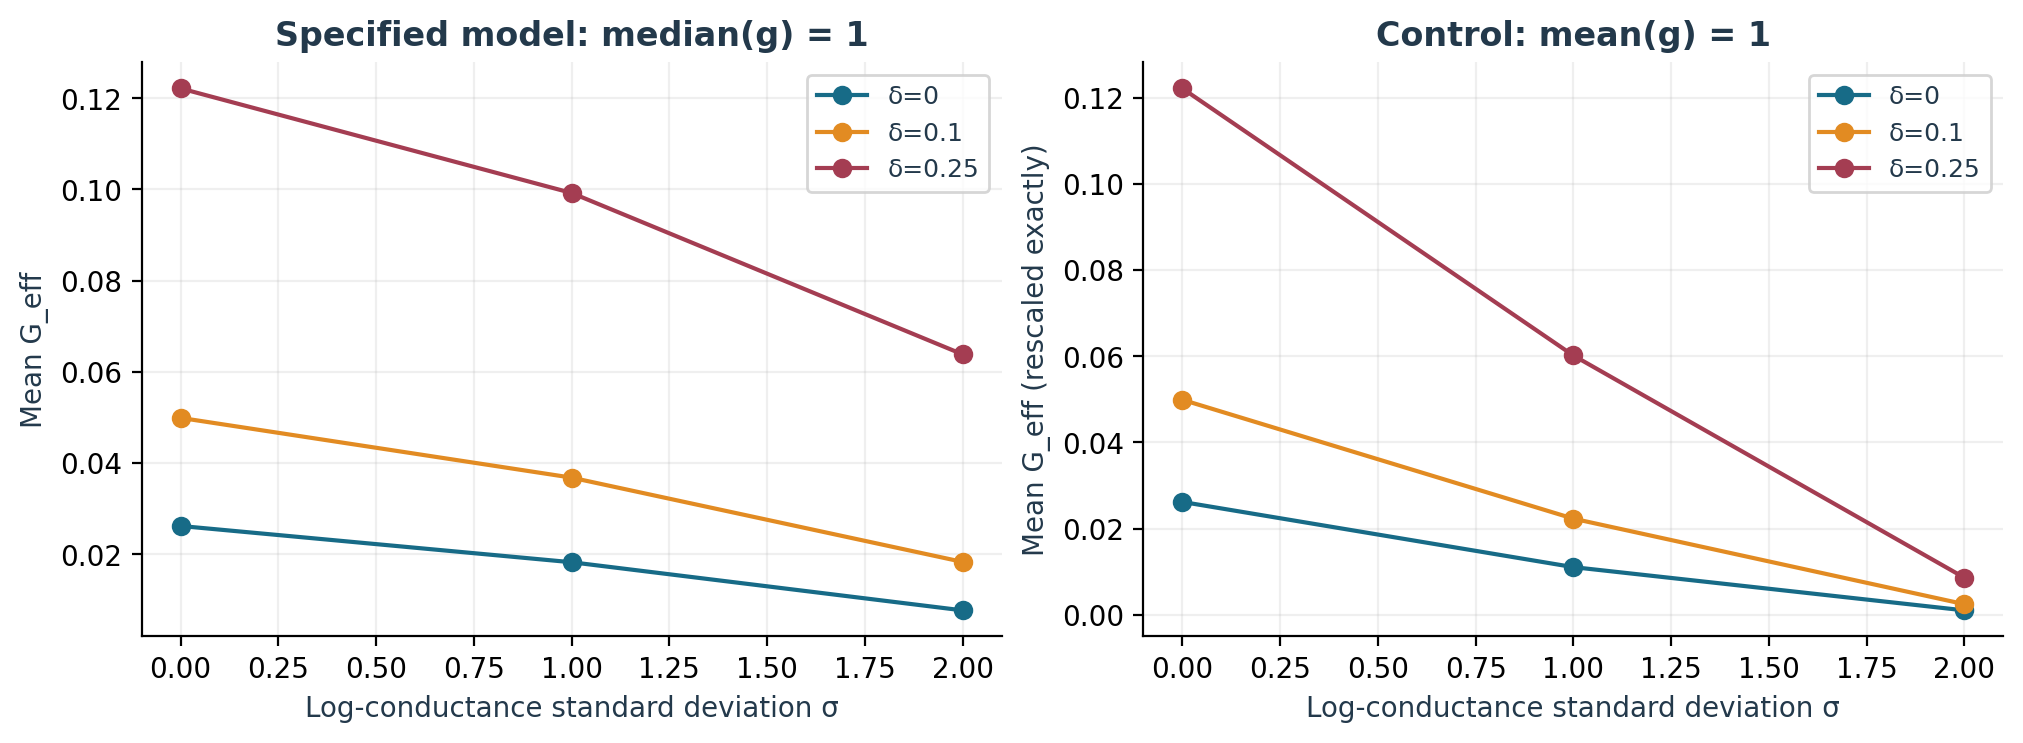

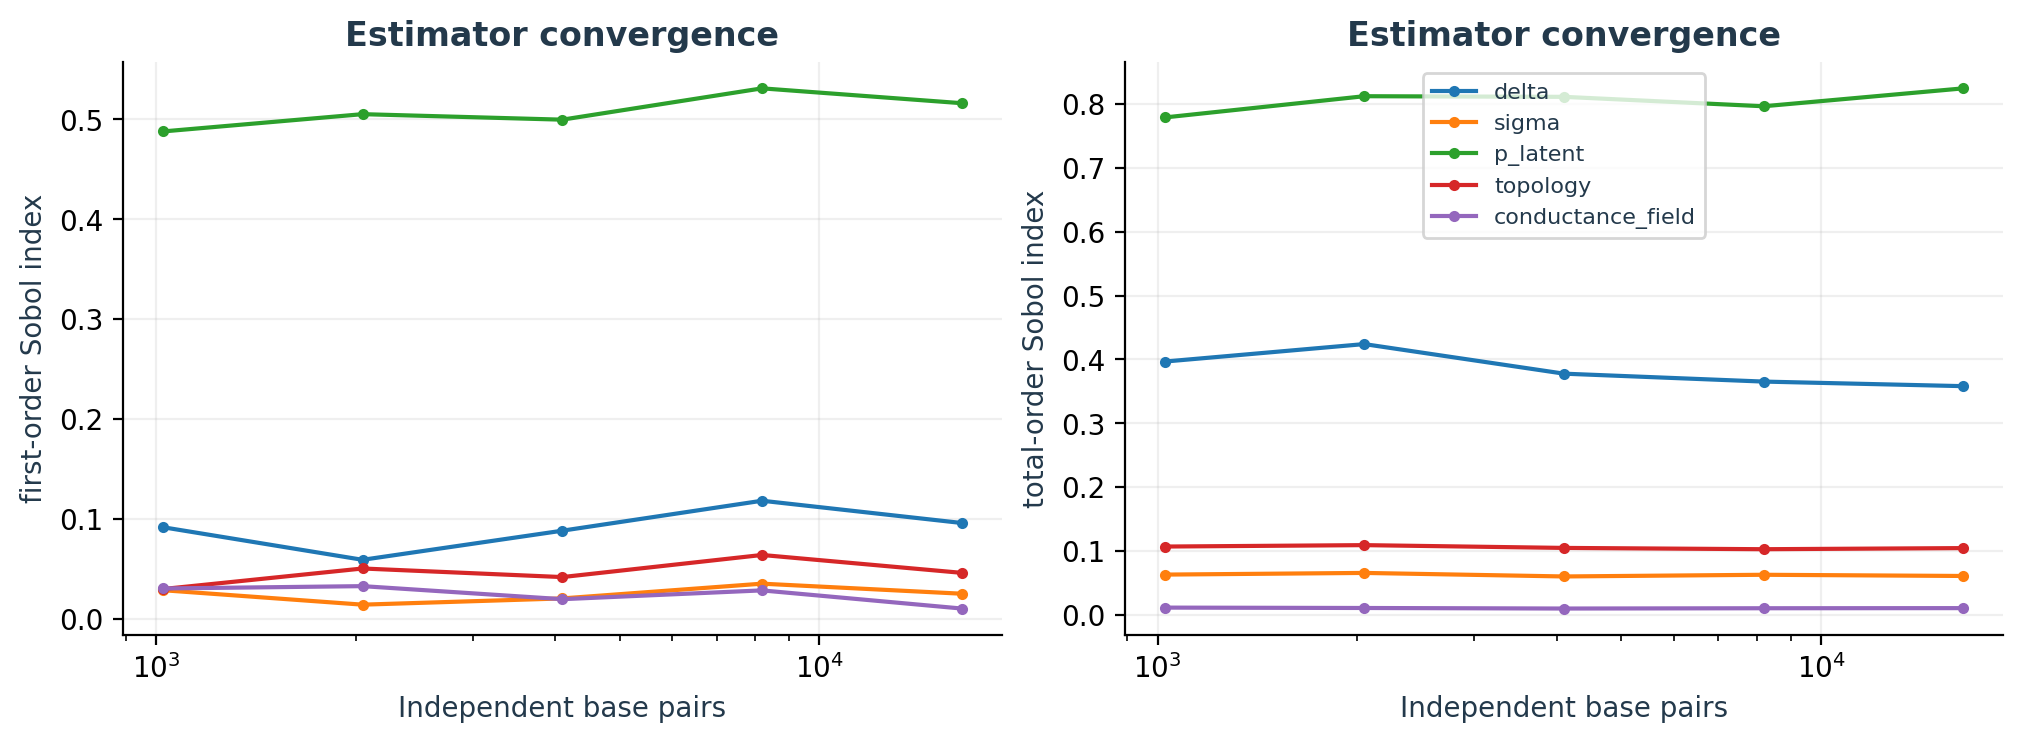

In [8]:
for name in ["06_convergence", "07_normalization", "08_sobol_convergence"]:
    display(Image(filename=str(FIG/(name+".png")), width=950))

In [9]:
manifest = json.loads((RES/"manifest.json").read_text())
diag = pd.read_csv(RES/"solver_diagnostics.csv")
display(manifest)
display(diag[["max_residual","relative_balance_error","energy_error"]].max().to_frame("maximum"))

{'seed': 20261104,
 'streams': {'scenarios': 1,
  'sweep': 2,
  'size': 3,
  'sobol': 4,
  'bootstrap': 5,
  'diagnostics': 6},
 'arguments': {'scenario_reps': 10000,
  'sweep_reps': 2500,
  'size_reps': 5000,
  'sobol_base': 16384,
  'bootstrap': 1000,
  'diagnostics': 1000},
 'n_baseline': 25,
 'delta_range': [0, 0.25],
 'sigma_range': [0, 2],
 'python': '3.12.14',
 'numpy': '2.3.5',
 'scipy': '1.17.0',
 'pandas': '2.2.3',
 'elapsed_seconds': 188.064472965,
 'solver_calls': 248188,
 'model': 'ln(g) ~ Normal(0, sigma^2); p=.5+delta*a, a~Uniform(-1,1)',
 'sobol': '5 independent groups; Jansen first/total; paired-row percentile bootstrap; raw estimates unclipped',
 'mean_ci': 'normal Monte Carlo 95%, not a model prediction interval',
 'spanning_ci': 'Wilson binomial 95%',
 'quantile_ci': 'binomial order-statistic 95%, conservative in the presence of ties'}

,maximum
max_residual,2.747108e-13
relative_balance_error,7.905149e-12
energy_error,2.411682e-13


## محدودیت و بازتولید

مدل بی‌بُعد، دوبعدی، پایا، خطی و کالیبره‌نشده است. اعتبارسنجی عددی، اعتبار پیش‌بینی سنگ واقعی را اثبات نمی‌کند. رتبه حساسیت به توزیع‌ها و دامنه ورودی وابسته است.

از ریشه مخزن:
```bash
python -m pip install -r requirements.txt
python -m pip install -e .
make all
```

منابع: Jansen (1999), doi:10.1016/S0010-4655(98)00154-4؛ Kesten (1980), doi:10.1007/BF01197577. جزئیات و تفسیر کامل در گزارش‌ها آمده است.